In [7]:
import os, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

for folder in ["Dataset", "Output", "Reports"]:
    os.makedirs(folder, exist_ok=True)
print("Libraries imported and project folders ready!")

Libraries imported and project folders ready!


In [28]:
stock_symbol = "RELIANCE.NS"
try:
    raw = yf.download(stock_symbol, period="5y", interval="1d",auto_adjust=True, progress=False,multi_level_index=False)
    if raw.empty:
        raise ValueError("No data returned by Yahoo Finance")
    yahoo_data = raw[["Open", "High", "Low", "Close", "Volume"]].copy()
    yahoo_data.index.name = "Date"
    yahoo_data.to_csv("Dataset/yahoo_stock_data.csv")
    yahoo_source = "Yahoo Finance downloaded data"
except Exception as e:
    print("Download unavailable:", e)
    sample = pd.read_csv("Dataset/yahoo_format_SAMPLE_RELIANCE.csv", parse_dates=["Date"])
    yahoo_data = sample.set_index("Date")[["Open", "High", "Low", "Close", "Volume"]]
    yahoo_source = "Synthetic sample (not actual market data)"
print("Yahoo data source:", yahoo_source)
display(yahoo_data.head())

Yahoo data source: Yahoo Finance downloaded data


,Open,High,Low,Close,Volume
Date,,,,,
2021-11-23,1056.680174,1087.569253,1045.787568,1080.594238,25326999
2021-11-24,1077.944621,1091.486849,1061.435777,1064.991211,16820296
2021-11-25,1074.774156,1133.200530,1067.595362,1129.101562,42401936
2021-11-26,1117.710975,1122.149578,1087.682539,1092.709961,15763138
2021-11-29,1104.712124,1132.294831,1086.595319,1105.799072,24325354


In [9]:
kaggle_path = "Dataset/kaggle_stock_data.csv"
if not os.path.exists(kaggle_path):
    kaggle_path = "Dataset/kaggle_format_SAMPLE_multiple_stocks.csv"
kaggle_data = pd.read_csv(kaggle_path, parse_dates=["Date"])
print("Kaggle-format file:", kaggle_path)
display(kaggle_data.head())
print("Yahoo shape:", yahoo_data.shape)

print("Kaggle shape:", kaggle_data.shape)

Kaggle-format file: Dataset/kaggle_format_SAMPLE_multiple_stocks.csv


,Date,Symbol,Open,High,Low,Close,Volume
0,2021-11-19,RELIANCE.NS,2407.37,2434.95,2363.30,2374.21,6503102
1,2021-11-22,RELIANCE.NS,2367.84,2393.81,2351.47,2382.94,2267577
2,2021-11-23,RELIANCE.NS,2385.28,2389.66,2301.95,2321.20,7841564
3,2021-11-24,RELIANCE.NS,2323.16,2385.69,2312.43,2367.71,331210
4,2021-11-25,RELIANCE.NS,2364.85,2416.24,2347.62,2389.68,6395385


Yahoo shape: (1237, 5)
Kaggle shape: (6520, 7)


In [10]:
display(yahoo_data.head())
display(yahoo_data.tail())
display(kaggle_data.head())
display(kaggle_data.tail())

print("YAHOO INFO")
yahoo_data.info()

print("\nKAGGLE INFO")
kaggle_data.info()

,Open,High,Low,Close,Volume
Date,,,,,
2021-11-23,1056.679936,1087.569008,1045.787332,1080.593994,25326999
2021-11-24,1077.944621,1091.486849,1061.435777,1064.991211,16820296
2021-11-25,1074.774272,1133.200653,1067.595477,1129.101685,42401936
2021-11-26,1117.710850,1122.149452,1087.682418,1092.709839,15763138
2021-11-29,1104.712246,1132.294956,1086.595439,1105.799194,24325354


,Open,High,Low,Close,Volume
Date,,,,,
2026-11-17,1339.000000,1374.0,1335.000000,1367.000000,15905595
2026-11-18,1370.000000,1376.5,1354.000000,1363.000000,18228940
2026-11-19,1361.900024,1382.5,1349.699951,1375.599976,14486599
2026-11-20,1369.000000,1383.0,1356.099976,1377.500000,13167730
2026-11-23,1381.000000,1390.0,1346.900024,1351.000000,15392522


,Date,Symbol,Open,High,Low,Close,Volume
0,2021-11-19,RELIANCE.NS,2407.37,2434.95,2363.30,2374.21,6503102
1,2021-11-22,RELIANCE.NS,2367.84,2393.81,2351.47,2382.94,2267577
2,2021-11-23,RELIANCE.NS,2385.28,2389.66,2301.95,2321.20,7841564
3,2021-11-24,RELIANCE.NS,2323.16,2385.69,2312.43,2367.71,331210
4,2021-11-25,RELIANCE.NS,2364.85,2416.24,2347.62,2389.68,6395385


,Date,Symbol,Open,High,Low,Close,Volume
6515,2026-11-12,TATAMOTORS.NS,902.50,911.39,901.40,906.06,3055548
6516,2026-11-13,TATAMOTORS.NS,903.17,913.00,854.46,858.53,1448628
6517,2026-11-16,TATAMOTORS.NS,856.78,885.12,850.90,875.64,2482241
6518,2026-11-17,TATAMOTORS.NS,873.09,881.08,855.24,864.56,1859440
6519,2026-11-18,TATAMOTORS.NS,874.61,886.04,866.64,877.98,2868121


YAHOO INFO
<class 'pandas.DataFrame'>
DatetimeIndex: 1237 entries, 2021-11-23 to 2026-11-23
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    1237 non-null   float64
 1   High    1237 non-null   float64
 2   Low     1237 non-null   float64
 3   Close   1237 non-null   float64
 4   Volume  1237 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 58.0 KB

KAGGLE INFO
<class 'pandas.DataFrame'>
RangeIndex: 6520 entries, 0 to 6519
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    6520 non-null   datetime64[us]
 1   Symbol  6520 non-null   str           
 2   Open    6520 non-null   float64       
 3   High    6520 non-null   float64       
 4   Low     6520 non-null   float64       
 5   Close   6520 non-null   float64       
 6   Volume  6520 non-null   int64         
dtypes: datetime64[us](1), float64(4), int64(1), str(1)
memory

In [11]:
display(yahoo_data.describe())
display(kaggle_data.describe(include="all"))

for name, data in [("Yahoo", yahoo_data), ("Kaggle", kaggle_data)]:
    print("\n", name, "shape:", data.shape)
    print("Columns:", data.columns.tolist())
    print("Types:\n", data.dtypes)
    print("Missing:\n", data.isna().sum())
    print("Duplicates:", data.duplicated().sum())

print("\nCompany counts:")

print(kaggle_data["Symbol"].value_counts())

,Open,High,Low,Close,Volume
count,1237.000000,1237.000000,1237.000000,1237.000000,1.237000e+03
mean,1277.139808,1288.591800,1265.530913,1276.738664,1.345833e+07
std,142.132900,142.751826,141.528271,142.076111,7.129903e+06
min,1001.628023,1008.758398,987.361121,1000.238464,0.000000e+00
25%,1158.709022,1170.135989,1149.636271,1159.469727,8.870660e+06
50%,1259.374079,1272.708939,1249.170142,1261.802979,1.188466e+07
75%,1403.013092,1414.460091,1388.579805,1401.647217,1.624937e+07
max,1585.668486,1604.382010,1570.936597,1584.971802,8.812112e+07


,Date,Symbol,Open,High,Low,Close,Volume
count,6520,6520,6520.000000,6520.000000,6520.000000,6520.000000,6.520000e+03
unique,NaN,5,NaN,NaN,NaN,NaN,NaN
top,NaN,RELIANCE.NS,NaN,NaN,NaN,NaN,NaN
freq,NaN,1304,NaN,NaN,NaN,NaN,NaN
mean,2024-05-19 21:36:26.503067,NaN,2417.938456,2448.608462,2388.108563,2418.575294,4.148388e+06
min,2021-11-19 00:00:00,NaN,377.480000,382.740000,373.380000,377.080000,3.041080e+05
25%,2023-02-19 06:00:00,NaN,1437.647500,1453.472500,1421.577500,1437.905000,2.203782e+06
50%,2024-05-20 12:00:00,NaN,2239.420000,2265.285000,2211.685000,2241.310000,4.123279e+06
75%,2025-08-19 06:00:00,NaN,3607.510000,3651.772500,3562.110000,3611.427500,6.130661e+06
max,2026-11-18 00:00:00,NaN,5722.240000,5784.430000,5675.650000,5700.010000,7.998915e+06



 Yahoo shape: (1237, 5)
Columns: ['Open', 'High', 'Low', 'Close', 'Volume']
Types:
 Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object
Missing:
 Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Duplicates: 0

 Kaggle shape: (6520, 7)
Columns: ['Date', 'Symbol', 'Open', 'High', 'Low', 'Close', 'Volume']
Types:
 Date      datetime64[us]
Symbol               str
Open             float64
High             float64
Low              float64
Close            float64
Volume             int64
dtype: object
Missing:
 Date      0
Symbol    0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Duplicates: 0

Company counts:
Symbol
RELIANCE.NS      1304
TCS.NS           1304
INFY.NS          1304
HDFCBANK.NS      1304
TATAMOTORS.NS    1304
Name: count, dtype: int64


In [12]:
def clean_ohlcv(data, date_column=None):
    result = data.copy()
    if date_column and date_column in result.columns:
        result[date_column] = pd.to_datetime(result[date_column], errors="coerce")
        result = result.dropna(subset=[date_column]).set_index(date_column)
    result.index = pd.to_datetime(result.index, errors="coerce")
    result = result.loc[~result.index.isna()].sort_index()
    result = result[~result.index.duplicated(keep="first")]
    cols = ["Open", "High", "Low", "Close", "Volume"]
    for col in cols:
        if col in result:
            result[col] = pd.to_numeric(result[col], errors="coerce")
    price_cols = ["Open", "High", "Low", "Close"]
    result = result.dropna(subset=price_cols)
    result = result[(result[price_cols] > 0).all(axis=1)]
    result["Volume"] = result["Volume"].fillna(0)
    result = result[result["Volume"] >= 0]
    return result

yahoo_clean = clean_ohlcv(yahoo_data)
kaggle_frames = []
for symbol, group in kaggle_data.groupby("Symbol"):
    cleaned = clean_ohlcv(group, "Date")
    cleaned["Symbol"] = symbol
    kaggle_frames.append(cleaned.reset_index(names="Date"))
kaggle_clean = pd.concat(kaggle_frames, ignore_index=True)
print("Yahoo rows:", len(yahoo_data), "->", len(yahoo_clean))
print("Kaggle rows:", len(kaggle_data), "->", len(kaggle_clean))
yahoo_clean.to_csv("Dataset/yahoo_stock_data_cleaned.csv")
kaggle_clean.to_csv("Dataset/kaggle_stock_data_cleaned.csv", index=False)

Yahoo rows: 1237 -> 1237
Kaggle rows: 6520 -> 6520


In [13]:
print("Highest price:", yahoo_clean["High"].max())
print("Lowest price:", yahoo_clean["Low"].min())
print("Average close:", yahoo_clean["Close"].mean())
print("Maximum volume:", yahoo_clean["Volume"].max())
print("Average volume:", yahoo_clean["Volume"].mean())

yahoo_analysis = yahoo_clean.copy()
yahoo_analysis["Daily_Change"] = yahoo_analysis["Close"].diff()
yahoo_analysis["Percentage_Change"] = yahoo_analysis["Close"].pct_change() * 100
display(yahoo_analysis[["Close", "Daily_Change", "Percentage_Change"]].head(10))

print("Highest price date:", yahoo_analysis["High"].idxmax())
print("Lowest price date:", yahoo_analysis["Low"].idxmin())

Highest price: 1604.3820104615531
Lowest price: 987.3611211647836
Average close: 1276.7386644343358
Maximum volume: 88121121
Average volume: 13458331.67825384


,Close,Daily_Change,Percentage_Change
Date,,,
2021-11-23,1080.593994,NaN,NaN
2021-11-24,1064.991211,-15.602783,-1.443908
2021-11-25,1129.101685,64.110474,6.019812
2021-11-26,1092.709839,-36.391846,-3.223080
2021-11-29,1105.799194,13.089355,1.197880
2021-11-30,1089.448730,-16.350464,-1.478611
2021-12-01,1117.348511,27.899780,2.560908
2021-12-02,1124.527344,7.178833,0.642488
2021-12-03,1090.739624,-33.787720,-3.004615


Highest price date: 2026-01-05 00:00:00
Lowest price date: 2022-03-08 00:00:00


In [14]:
prices = yahoo_analysis["Close"].to_numpy()
print("Mean:", np.mean(prices))
print("Median:", np.median(prices))
print("Standard deviation:", np.std(prices))
print("Maximum:", np.max(prices))
print("Minimum:", np.min(prices))
returns = np.diff(prices) / prices[:-1] * 100
print("First 10 daily returns:", returns[:10])

initial, latest = prices[0], prices[-1]
print("Total price change:", latest - initial)
print("Total percentage change:", (latest / initial - 1) * 100, "%")

Mean: 1276.7386644343358
Median: 1261.802978515625
Standard deviation: 142.01867155571898
Maximum: 1584.9718017578125
Minimum: 1000.2384643554688
First 10 daily returns: [-1.44390801  6.01981246 -3.22307957  1.19788026 -1.47861058  2.56090805
  0.64248826 -3.00461522 -1.89557442  0.81477643]
Total price change: 270.406005859375
Total percentage change: 25.02383016429992 %


In [15]:
yahoo_analysis["MA20"] = yahoo_analysis["Close"].rolling(20).mean()
yahoo_analysis["MA50"] = yahoo_analysis["Close"].rolling(50).mean()
yahoo_analysis["MA100"] = yahoo_analysis["Close"].rolling(100).mean()
yahoo_analysis["Volatility20"] = yahoo_analysis["Percentage_Change"].rolling(20).std()
display(yahoo_analysis[["Close", "MA20", "MA50", "MA100", "Volatility20"]].tail(10))
last = yahoo_analysis.dropna(subset=["MA20", "MA50"]).iloc[-1]
print("MA20 above MA50" if last["MA20"] > last["MA50"] else "MA20 at/below MA50")

,Close,MA20,MA50,MA100,Volatility20
Date,,,,,
2026-11-09,1324.400024,1223.845001,1236.118000,1271.065001,2.881920
2026-11-11,1335.400024,1232.670001,1237.182002,1271.092002,2.856276
2026-11-12,1339.699951,1241.320001,1238.236001,1271.208002,2.857839
2026-11-13,1339.699951,1249.575000,1239.490000,1271.510001,2.862511
2026-11-16,1344.800049,1256.065002,1240.206001,1271.693002,2.789017
2026-11-17,1367.000000,1263.855005,1241.284001,1272.268002,2.791844
2026-11-18,1363.000000,1271.905005,1242.494001,1272.762002,2.781440
2026-11-19,1375.599976,1280.235004,1243.566001,1273.337002,2.781956
2026-11-20,1377.500000,1289.885004,1244.926001,1274.102002,2.712263


MA20 above MA50


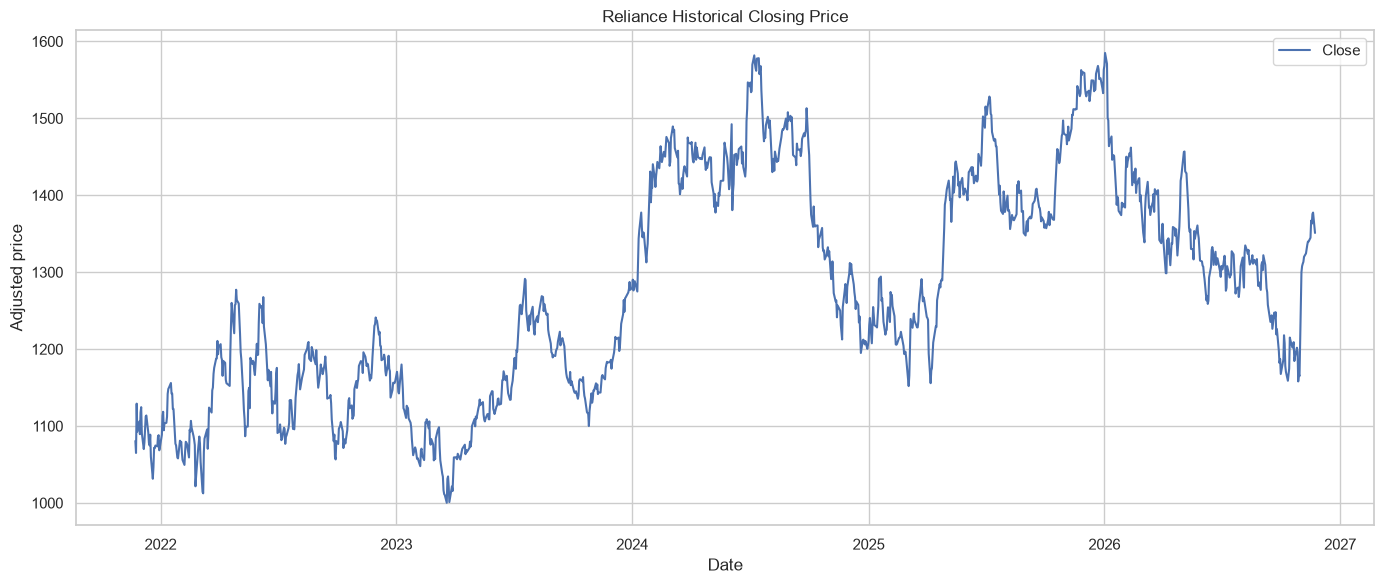

In [16]:
plt.figure(figsize=(14,6))
plt.plot(yahoo_analysis.index, yahoo_analysis["Close"], label="Close")
plt.title("Reliance Historical Closing Price"); plt.xlabel("Date"); plt.ylabel("Adjusted price")
plt.legend(); plt.tight_layout(); plt.savefig("Output/stock_price.png"); plt.show()

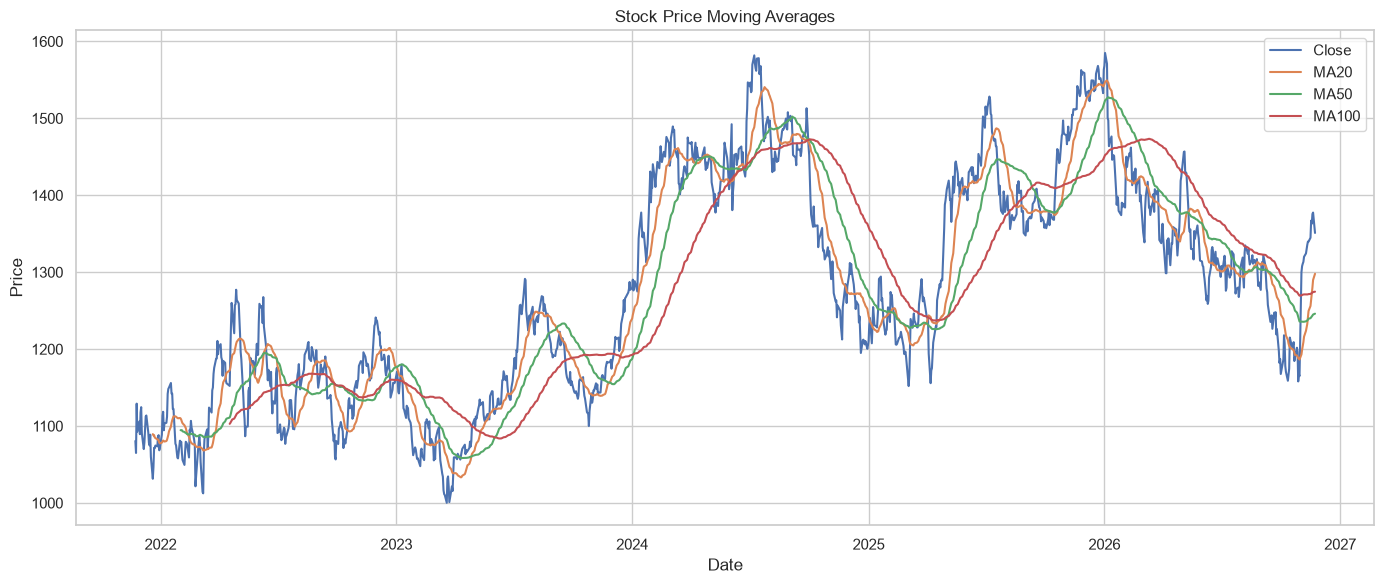

In [17]:
plt.figure(figsize=(14,6))
for col in ["Close","MA20","MA50","MA100"]:
    plt.plot(yahoo_analysis.index, yahoo_analysis[col], label=col)
plt.title("Stock Price Moving Averages"); plt.xlabel("Date"); plt.ylabel("Price")
plt.legend(); plt.tight_layout(); plt.savefig("Output/moving_average.png"); plt.show()

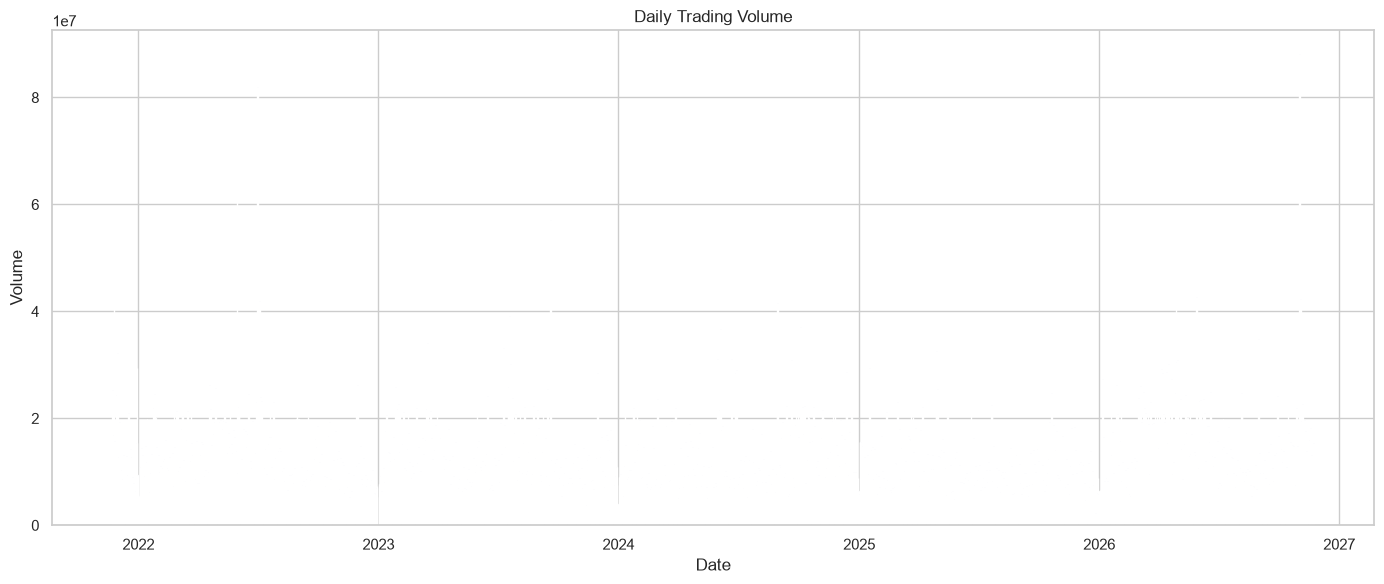

In [18]:
plt.figure(figsize=(14,6))
plt.bar(yahoo_analysis.index, yahoo_analysis["Volume"], width=1)
plt.title("Daily Trading Volume"); plt.xlabel("Date"); plt.ylabel("Volume")
plt.tight_layout(); plt.savefig("Output/trading_volume.png"); plt.show()

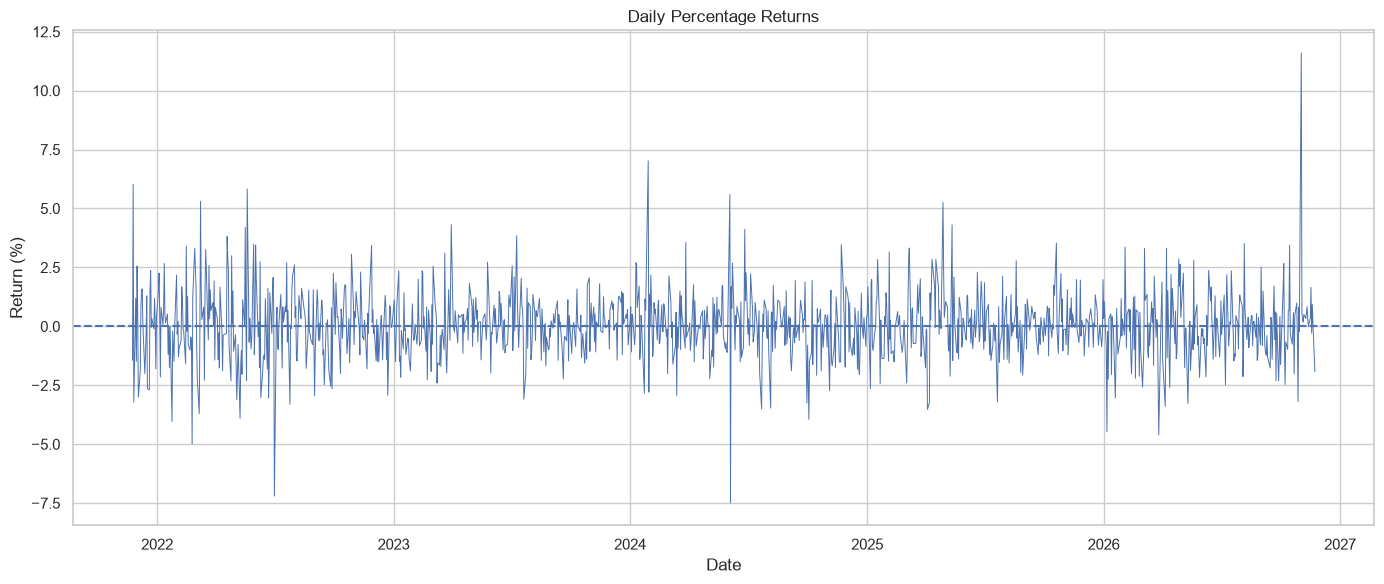

In [19]:
plt.figure(figsize=(14,6))
plt.plot(yahoo_analysis.index, yahoo_analysis["Percentage_Change"], linewidth=.7)
plt.axhline(0, linestyle="--"); plt.title("Daily Percentage Returns")
plt.xlabel("Date"); plt.ylabel("Return (%)")
plt.tight_layout(); plt.savefig("Output/daily_returns.png"); plt.show()

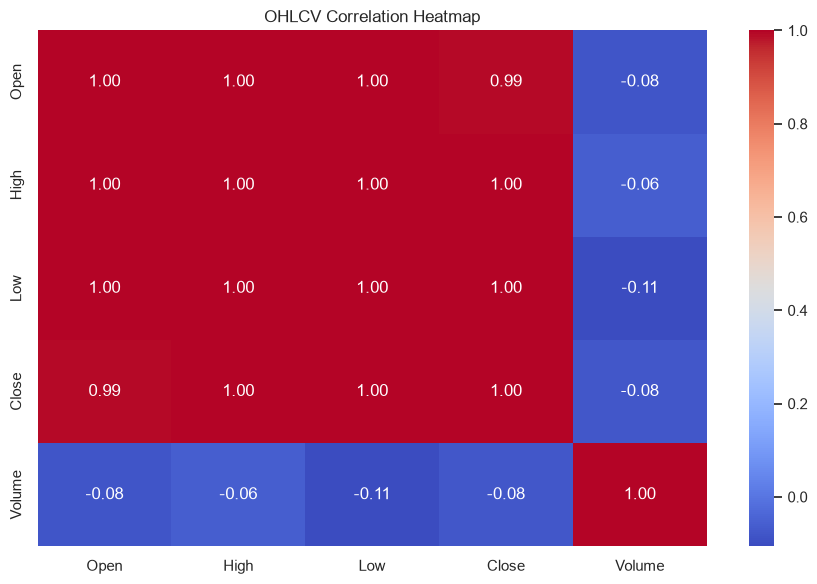

In [20]:
corr = yahoo_analysis[["Open","High","Low","Close","Volume"]].corr()
plt.figure(figsize=(9,6)); sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("OHLCV Correlation Heatmap"); plt.tight_layout()
plt.savefig("Output/correlation_heatmap.png"); plt.show()

In [27]:
symbols = ["RELIANCE.NS","TCS.NS","INFY.NS","HDFCBANK.NS","TATAMOTORS.NS"]
try:
    multi = yf.download(symbols, period="1y", interval="1d", auto_adjust=True,
                        progress=False, multi_level_index=True)
    if multi.empty:
        raise ValueError("No multi-company data returned")
    close_prices = multi["Close"]
    comparison_source = "Yahoo Finance"
except Exception as e:
    print("Multi-company download unavailable:", e)
    close_prices = kaggle_clean.pivot(index="Date", columns="Symbol", values="Close")
    comparison_source = "Kaggle-format CSV source: " + ("sample" if "SAMPLE" in kaggle_path else "user CSV")

print("Comparison source:", comparison_source)
display(close_prices.head())

HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: TATAMOTORS.NS"}}}
$TATAMOTORS.NS: No data found, symbol may be delisted

1 Failed download:
['TATAMOTORS.NS']: No data found, symbol may be delisted


Comparison source: Yahoo Finance


Ticker,HDFCBANK.NS,INFY.NS,RELIANCE.NS,TATAMOTORS.NS,TCS.NS
Date,,,,,
2025-11-24,982.893494,1481.279419,1528.831299,NaN,3011.238281
2025-11-25,973.695618,1464.629272,1532.613770,NaN,2990.148682
2025-11-26,987.566223,1490.752686,1562.674805,NaN,3032.040527
2025-11-27,993.075073,1498.886353,1556.204712,NaN,3006.828613
2025-11-28,991.205994,1492.857788,1560.285889,NaN,3007.691162


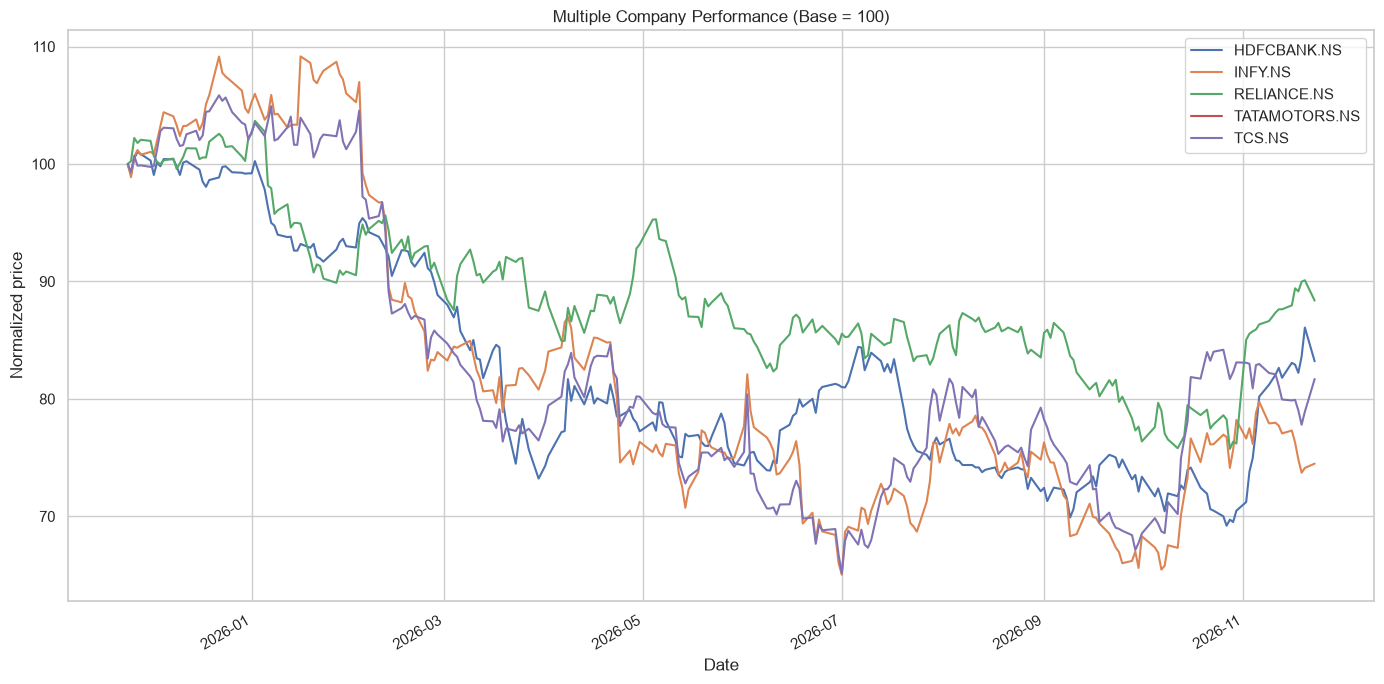

,Average Daily Return (%),Annualized Volatility (%)
Ticker,,
HDFCBANK.NS,-0.063485,23.843632
INFY.NS,-0.099772,31.681373
RELIANCE.NS,-0.038680,24.386560
TATAMOTORS.NS,NaN,NaN
TCS.NS,-0.063835,30.415535


In [22]:
normalized = close_prices.dropna(how="all").ffill()
normalized = normalized / normalized.bfill().iloc[0] * 100
normalized.plot(figsize=(14,7))
plt.title("Multiple Company Performance (Base = 100)")
plt.xlabel("Date"); plt.ylabel("Normalized price")
plt.legend(); plt.tight_layout()
plt.savefig("Output/multiple_company_comparison.png"); plt.show()
daily_returns = close_prices.pct_change()
summary = pd.DataFrame({"Average Daily Return (%)": daily_returns.mean() * 100,"Annualized Volatility (%)": daily_returns.std() * np.sqrt(252) * 100})
display(summary)

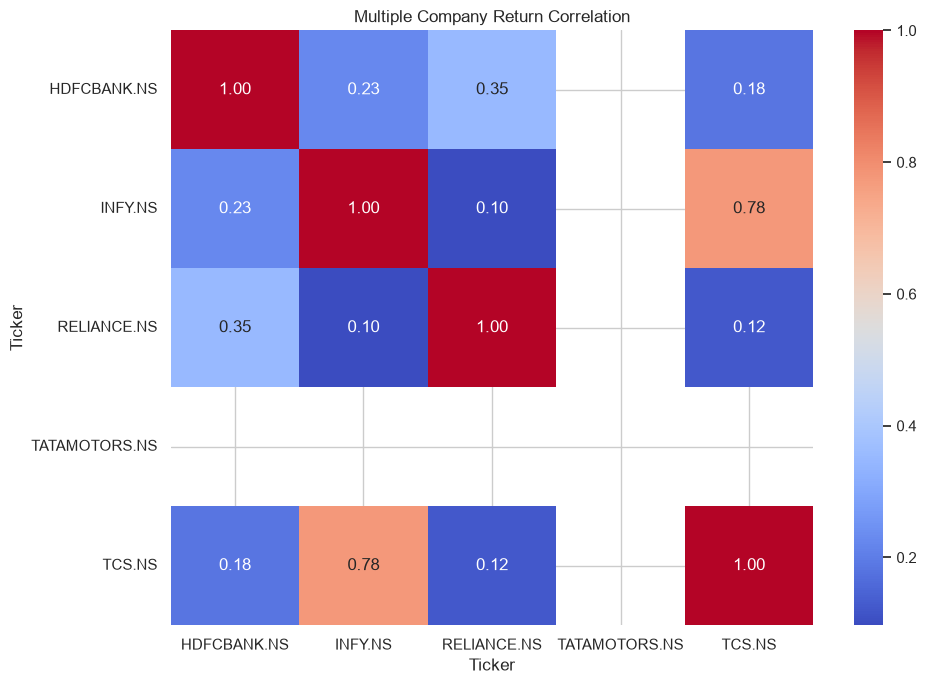

In [23]:
plt.figure(figsize=(10,7))
sns.heatmap(daily_returns.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Multiple Company Return Correlation")
plt.tight_layout(); plt.savefig("Output/multiple_company_correlation.png"); plt.show()

Highest Price : 1604.3820104615531
Lowest Price : 987.3611211647836
Average Closing Price : 1276.7386644343358
Maximum Volume : 88121121
Average Volume : 13458331.67825384
Total Records : 1237


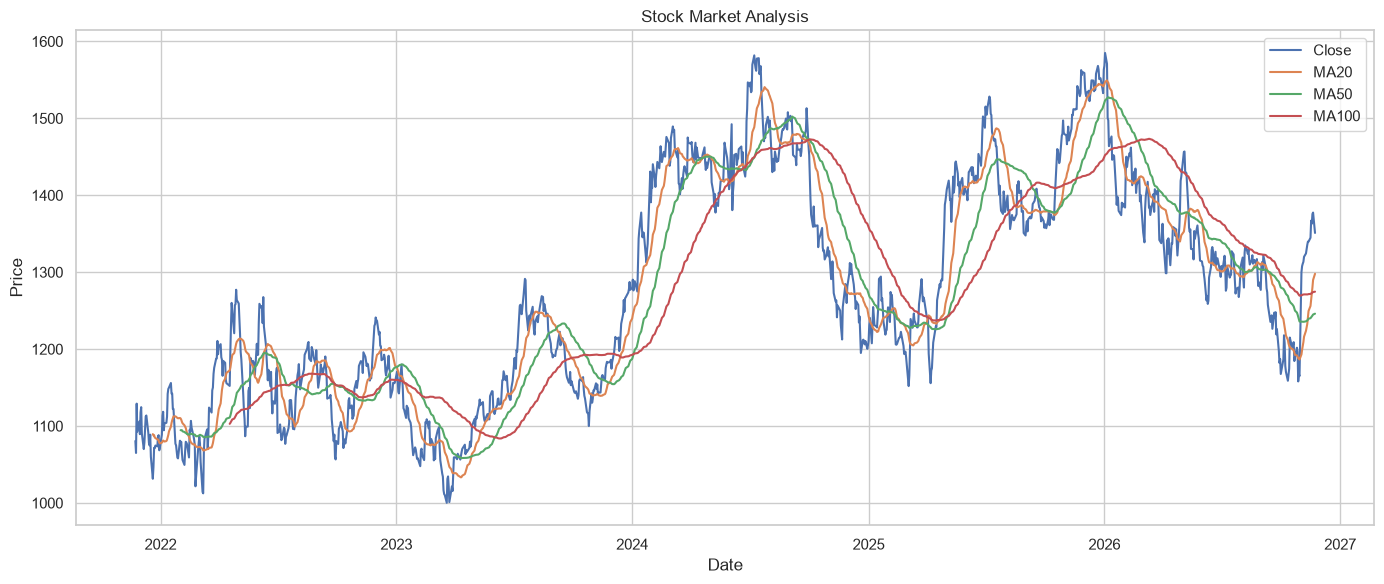

Report saved: Reports/stock_analysis_report.csv


In [24]:
def calculate_metrics(data):
    return {"Highest Price": data["High"].max(),"Lowest Price": data["Low"].min(),"Average Closing Price": data["Close"].mean(),"Maximum Volume": data["Volume"].max(),"Average Volume": data["Volume"].mean(),"Total Records": len(data)}
def calculate_moving_averages(data):
    result = data.copy()
    for window in [20, 50, 100]:
        result[f"MA{window}"] = result["Close"].rolling(window).mean()
    return result

def visualize_stock(data, save_path=None):
    result = calculate_moving_averages(data)
    plt.figure(figsize=(14,6))
    for col in ["Close","MA20","MA50","MA100"]:
        plt.plot(result.index, result[col], label=col)
    plt.title("Stock Market Analysis"); plt.xlabel("Date"); plt.ylabel("Price")
    plt.legend(); plt.tight_layout()
    if save_path: plt.savefig(save_path)
    plt.show()
def export_report(data, path="Reports/stock_analysis_report.csv"):
    data.to_csv(path)
    print("Report saved:", path)

for key, value in calculate_metrics(yahoo_clean).items():
    print(key, ":", value)
visualize_stock(yahoo_clean, "Output/function_stock_plot.png")
export_report(yahoo_analysis)

In [25]:
tests = {
    "Yahoo dataset loaded": not yahoo_data.empty,
    "Kaggle dataset loaded": not kaggle_data.empty,
    "Cleaned Yahoo data available": not yahoo_clean.empty,
    "Moving average calculated": "MA20" in yahoo_analysis.columns,
    "Daily return calculated": "Percentage_Change" in yahoo_analysis.columns,
    "Report exported": os.path.exists("Reports/stock_analysis_report.csv"),
    "Price chart created": os.path.exists("Output/stock_price.png")
}
for name, passed in tests.items():
    print(name + ":", "PASS" if passed else "FAIL")
print("Passed", sum(tests.values()), "of", len(tests), "tests")

Yahoo dataset loaded: PASS
Kaggle dataset loaded: PASS
Cleaned Yahoo data available: PASS
Moving average calculated: PASS
Daily return calculated: PASS
Report exported: PASS
Price chart created: PASS
Passed 7 of 7 tests


In [26]:
yahoo_analysis.to_csv("Reports/reliance_complete_analysis.csv")
summary.to_csv("Reports/multiple_company_summary.csv")
for folder in ["Dataset", "Output", "Reports"]:
    print("\\n" + folder + "/")
    for filename in sorted(os.listdir(folder)):
        print(" -", filename)

\nDataset/
 - kaggle_format_SAMPLE_multiple_stocks.csv
 - kaggle_stock_data_cleaned.csv
 - yahoo_format_SAMPLE_RELIANCE.csv
 - yahoo_stock_data.csv
 - yahoo_stock_data_cleaned.csv
\nOutput/
 - correlation_heatmap.png
 - daily_returns.png
 - function_stock_plot.png
 - moving_average.png
 - multiple_company_comparison.png
 - multiple_company_correlation.png
 - stock_price.png
 - trading_volume.png
\nReports/
 - multiple_company_summary.csv
 - reliance_complete_analysis.csv
 - stock_analysis_report.csv
